# 3 · A/B testing growth experiments

Three experiments ran on consecutive signup cohorts with 50/50 random assignment:

| Experiment | Primary metric | Planted truth |
|---|---|---|
| `referral_nudge_banner` | transactions in first 30 days | **no effect** |
| `first_merchant_cashback` | 7-day activation | +~6pp |
| `simplified_kyc_flow` | KYC completion | +2.5pp |

Process: **design** (baseline, MDE, power, sample size) → **validity** (sample-ratio mismatch) →
**analysis** (z-test / Welch t-test, CIs, Holm correction) → **decision** on the primary metric only.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from upi import config, db, plots
from upi import abtest
con = db.connect()
if not db.marts_exist(con): db.build_marts(con)

## 1. Design: how many users do we need?

The baseline comes from the 3 cohorts *before* each test; 80% power, α = 0.05, two-sided.

In [2]:
um = pd.read_sql_query("SELECT cohort_month, days_observed, kyc_completed, activated_d7, txns_first_30d, active_d30_60 FROM user_metrics", con)
abtest.design_table(um).round(3)

,experiment,primary_metric,baseline,baseline_sd,mde,required_n_per_arm
0,referral_nudge_banner,txns_first_30d,3.183,3.552,+0.25 txns,3170
1,first_merchant_cashback,activated_d7,0.273,0.445,+3 pts,3575
2,simplified_kyc_flow,kyc_completed,0.830,0.375,+2 pts,5260


In [3]:
# How the required sample grows as the detectable effect shrinks (baseline 27% activation)
pd.DataFrame({"mde_pts": [1, 2, 3, 5],
              "n_per_arm": [abtest.sample_size_proportion(0.27, m / 100) for m in (1, 2, 3, 5)]})

,mde_pts,n_per_arm
0,1,31296
1,2,7910
2,3,3553
3,5,1304


## 2-3. Validity and results

In [4]:
outcomes = db.query(con, "07_experiment_outcomes.sql")
results, summaries = [], []
for spec in abtest.EXPERIMENTS:
    res, s = abtest.analyze_experiment(outcomes[outcomes.experiment_name == spec.name], spec.name, abtest.PLANS[spec.name])
    results.append(res); summaries.append(s)
results = pd.concat(results, ignore_index=True)
pd.DataFrame(summaries)[["experiment", "n_control", "n_treatment", "srm_p", "achieved_power", "decision"]]

,experiment,n_control,n_treatment,srm_p,achieved_power,decision
0,referral_nudge_banner,10228,10338,0.443058,0.998543,DON'T SHIP - well-powered test found no meanin...
1,first_merchant_cashback,9965,10021,0.692018,0.996610,SHIP
2,simplified_kyc_flow,11238,11299,0.684498,0.984495,SHIP


In [5]:
results[["experiment", "metric", "role", "control", "treatment", "diff", "ci_low", "ci_high", "p_value", "p_holm", "significant"]].round(4)

,experiment,metric,role,control,treatment,diff,ci_low,ci_high,p_value,p_holm,significant
0,referral_nudge_banner,txns_first_30d,primary,3.2671,3.2449,-0.0222,-0.1212,0.0768,0.6605,1.0000,False
1,referral_nudge_banner,activated_d7,secondary,0.2741,0.2719,-0.0021,-0.0143,0.0100,0.7303,1.0000,False
2,referral_nudge_banner,active_d30_60,guardrail,0.5259,0.5433,0.0174,0.0038,0.0311,0.0122,0.0367,True
3,first_merchant_cashback,activated_d7,primary,0.2752,0.3341,0.0589,0.0462,0.0717,0.0000,0.0000,True
4,first_merchant_cashback,active_d30_60,secondary,0.5315,0.5387,0.0072,-0.0066,0.0210,0.3070,0.3070,False
5,first_merchant_cashback,txns_first_30d,secondary,3.2896,3.4516,0.1619,0.0580,0.2659,0.0023,0.0045,True
6,simplified_kyc_flow,kyc_completed,primary,0.8324,0.8580,0.0255,0.0161,0.0349,0.0000,0.0000,True
7,simplified_kyc_flow,activated_d7,secondary,0.2802,0.2819,0.0017,-0.0103,0.0137,0.7773,0.7773,False


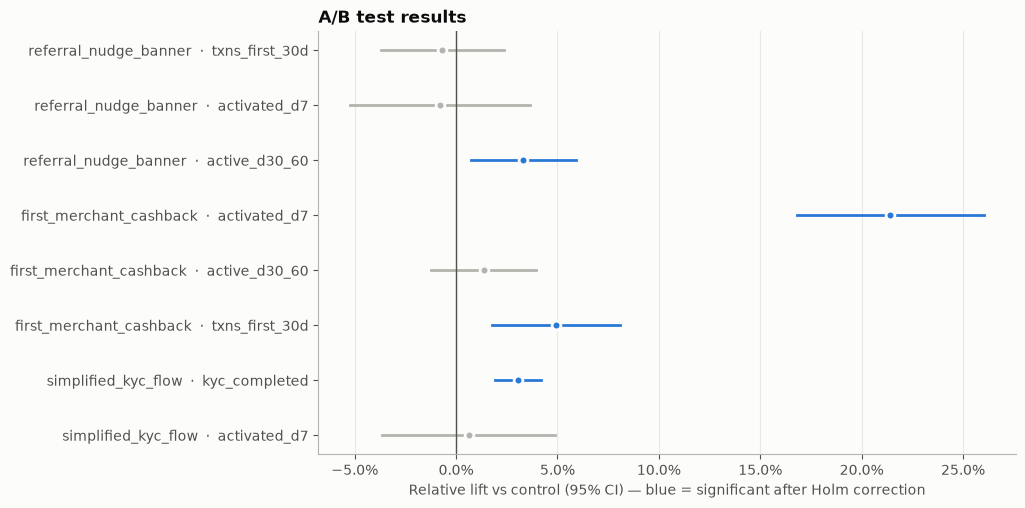

In [6]:
plots.ab_forest(results);

**Note the banner's `active_d30_60` guardrail.** It comes out "significant" even though the planted effect is
zero: a false positive. With 8 metrics tested at α = 0.05, some will cross the line by chance. That's why the ship
decision rests on the single pre-registered primary metric, which correctly shows nothing.

## 4. Heterogeneity (exploratory)

In [7]:
cb = outcomes[(outcomes.experiment_name == "first_merchant_cashback") & (outcomes.days_observed >= 7)]
abtest.segment_effects(cb, "activated_d7").round(4)

,channel,n,control,treatment,diff,ci_low,ci_high,p_value
0,organic,9910,0.2676,0.3301,0.0625,0.0446,0.0805,0.0000
1,paid,5007,0.2423,0.2853,0.0430,0.0186,0.0674,0.0006
2,referral,5069,0.3224,0.3901,0.0677,0.0414,0.0940,0.0000


## 5. Did we recover the truth?

In [8]:
import json
truth = json.loads((config.SIM_DIR / "ground_truth.json").read_text())["experiments"]
t = truth["first_merchant_cashback"]["true_activation_rate"]
r = results.query("experiment == 'first_merchant_cashback' and role == 'primary'").iloc[0]
print(f"cashback: planted {t['treatment'] - t['control']:+.4f}, estimated {r['diff']:+.4f} "
      f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")
t = truth["simplified_kyc_flow"]["true_kyc_rate"]
r = results.query("experiment == 'simplified_kyc_flow' and role == 'primary'").iloc[0]
print(f"KYC flow: planted {t['treatment'] - t['control']:+.4f}, estimated {r['diff']:+.4f} "
      f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")

cashback: planted +0.0628, estimated +0.0589 [+0.0462, +0.0717]
KYC flow: planted +0.0254, estimated +0.0255 [+0.0161, +0.0349]


## 6. Sanity check: is the false-positive rate really 5%?

Simulate 1,000 A/A tests (no true difference) and count how often p < 0.05.

In [9]:
rng = np.random.default_rng(0)
p = [abtest.two_proportion_test(*(lambda a, b: (a.sum(), len(a), b.sum(), len(b)))(rng.binomial(1, .27, 5000), rng.binomial(1, .27, 5000)))["p_value"] for _ in range(1000)]
print(f"A/A false-positive rate: {np.mean(np.array(p) < 0.05):.1%}")

A/A false-positive rate: 5.3%
